# ejemplo cnn gats vs perros

In [1]:
import numpy as np
import tensorflow_datasets as tfds
import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
tf.random.set_seed(0)

I0000 00:00:1792321144.803712   57329 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792321145.376170   57329 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792321149.263163   57329 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Create a sample NumPy array
data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

# Create a tf.data Dataset from the NumPy array
dataset = tf.data.Dataset.from_tensor_slices(data)

E0000 00:00:1792321153.247748   57329 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1792321153.248262   57422 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1792321153.277658   57329 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/jerry/anacon

In [3]:
for elem in dataset:
      print(elem.numpy())

1
2
3
4
5
6
7
8
9
10


In [4]:
buffer_size = 2

dataset = dataset.shuffle(buffer_size)

for elem in dataset:
      print(elem.numpy())

2
1
4
3
6
5
7
9
10
8


In [5]:
batch_size = 2

dataset = dataset.batch(batch_size)

for elem in dataset:
      print(elem.numpy())

[1 3]
[4 5]
[6 2]
[8 7]
[10  9]


In [6]:
# Create a sample text file
with open("sample.txt", "w") as f:
    f.write("This is a sample text file.\n")
    f.write("Each line represents an element in the dataset.\n")
    f.write("We can apply various transformations to the data.\n")
    f.write("This makes it easy to prepare data for training.\n")

# Create a tf.data Dataset from the text file
dataset = tf.data.TextLineDataset("sample.txt")
for elem in dataset:
      print(elem.numpy())

b'This is a sample text file.'
b'Each line represents an element in the dataset.'
b'We can apply various transformations to the data.'
b'This makes it easy to prepare data for training.'


In [7]:
# Define a preprocessing function
def preprocess_text(line):
    line = tf.strings.lower(line)
    line = tf.strings.strip(line)
    return line

# Apply the preprocessing function to the dataset
dataset = dataset.map(preprocess_text)

for elem in dataset:
      print(elem.numpy())

b'this is a sample text file.'
b'each line represents an element in the dataset.'
b'we can apply various transformations to the data.'
b'this makes it easy to prepare data for training.'


In [8]:
dataset, info = tfds.load('cats_vs_dogs', with_info=True, as_supervised=True)
dataset = dataset['train']
class_names = ['cat', 'dog']

size = tf.data.experimental.cardinality(dataset).numpy()
print(f'number of images:{size}')

number of images:23262


In [9]:
image_size = (96, 96, 3)


def preprocess_img(images, size=(96, 96)):
    return tf.image.resize(images, size)

dataset = dataset.map(lambda images, labels: (preprocess_img(images), labels))

In [10]:
batch_size = 32
train_size = int(0.75 * size)
val_size = int(0.1 * size)

train_ds = dataset.take(train_size)
train_ds = train_ds.shuffle(1000).batch(batch_size).cache()
remaining = dataset.skip(train_size)

val_ds = remaining.take(val_size)
test_ds = remaining.skip(val_size)

val_ds = val_ds.shuffle(1000).batch(batch_size).cache()
test_ds = test_ds.batch(batch_size).cache()

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

I0000 00:00:1792321154.441481   57546 tf_record_dataset_op.cc:398] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1792321155.012038   57555 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.


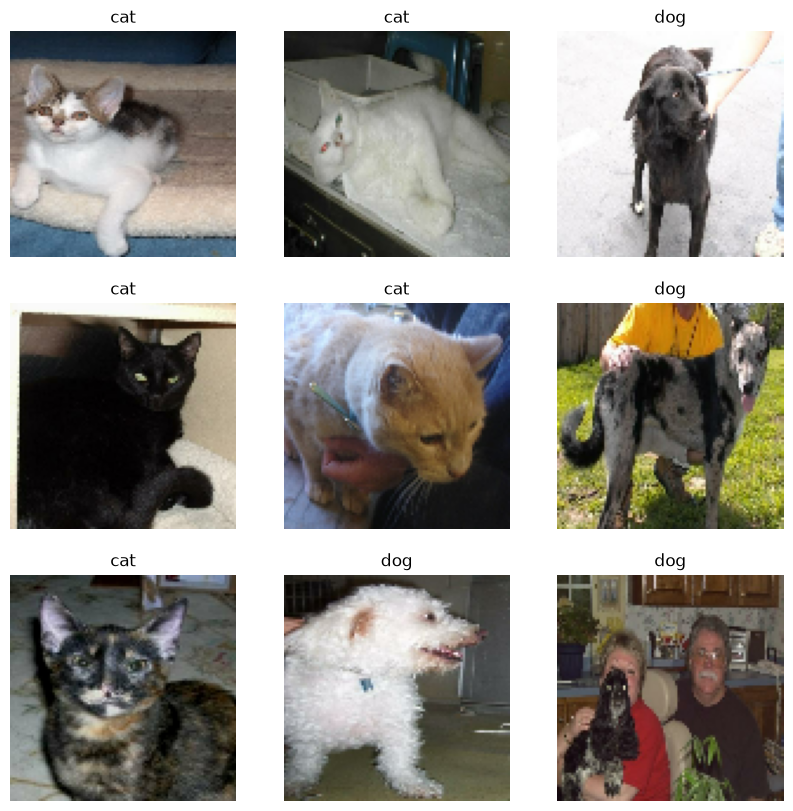

In [12]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [13]:
# Create a model with two convolutional layers without pooling and without any regularization

inputs = tf.keras.Input(shape=image_size, name='input')
reescaling = layers.Rescaling(1./255)(inputs)

# Conv Layer 1
conv_1 = layers.Conv2D(16, (3, 3), padding='same', activation='relu')(reescaling)

# Conv Layer 2
conv_2 = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(conv_1)


# Fully-connected
# Flattening
flat = layers.Flatten()(conv_2)
dense = layers.Dense(64, activation='relu')(flat)
outputs = layers.Dense(1, activation='sigmoid')(dense)

model_1 = tf.keras.Model(inputs=inputs, outputs=outputs)

In [14]:
model_1.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

In [15]:
epochs = 8

es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=2,  
    verbose=1)

history = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/8


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


546/546 ━━━━━━━━━━━━━━━━━━━━ 189s 342ms/step - accuracy: 0.6299 - loss: 0.7059 - val_accuracy: 0.6771 - val_loss: 0.5882
Epoch 2/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 167s 305ms/step - accuracy: 0.7423 - loss: 0.5139 - val_accuracy: 0.7218 - val_loss: 0.5479
Epoch 3/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 150s 276ms/step - accuracy: 0.8525 - loss: 0.3306 - val_accuracy: 0.7330 - val_loss: 0.6861
Epoch 4/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 149s 272ms/step - accuracy: 0.9335 - loss: 0.1724 - val_accuracy: 0.7077 - val_loss: 1.0895
Epoch 5/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 149s 273ms/step - accuracy: 0.9631 - loss: 0.0991 - val_accuracy: 0.7163 - val_loss: 1.1413
Epoch 6/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 151s 276ms/step - accuracy: 0.9811 - loss: 0.0581 - val_accuracy: 0.6986 - val_loss: 1.3287
Epoch 7/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 157s 287ms/step - accuracy: 0.9893 - loss: 0.0355 - val_accuracy: 0.7038 - val_loss: 1.3603
Epoch 8/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 156s 286ms/step - accuracy: 0.9928 - loss: 0.0255 - va

In [16]:
results = model_1.evaluate(test_ds, verbose=1)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))

110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.6946 - loss: 1.5817
Test Loss: 1.581657886505127
Test Accuracy: 0.6945558786392212


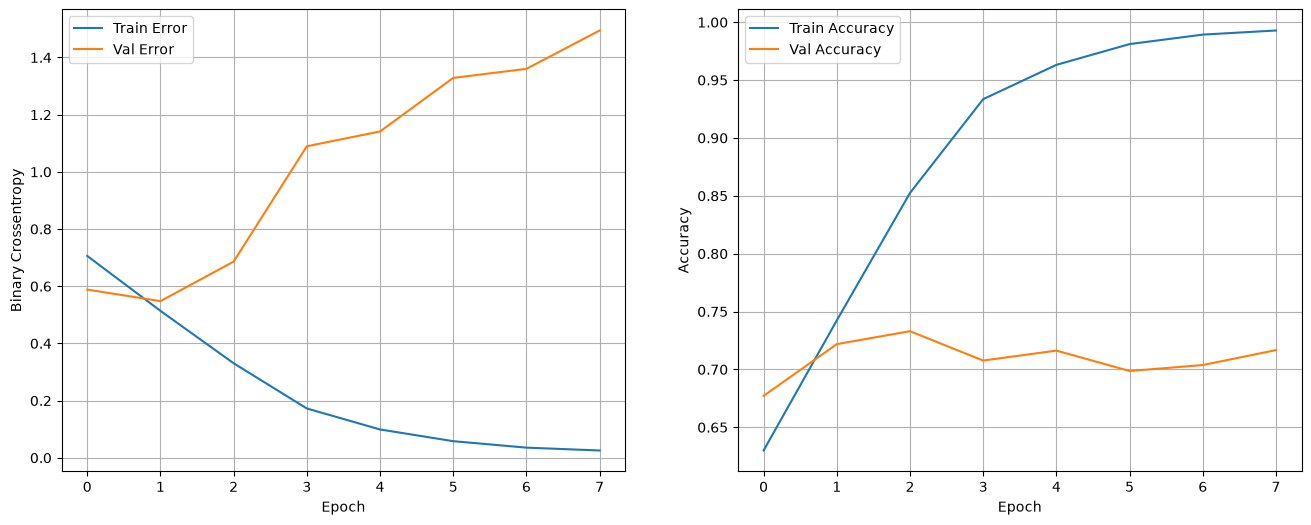

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


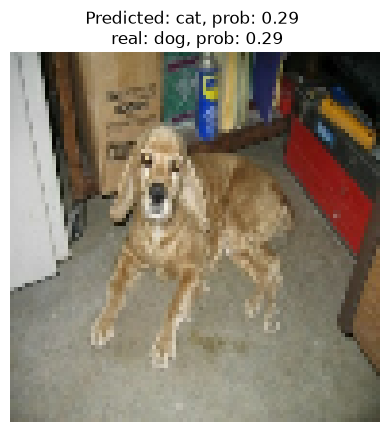

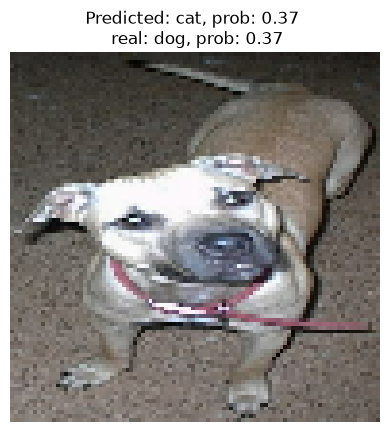

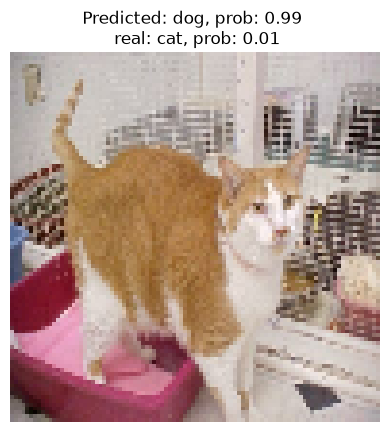

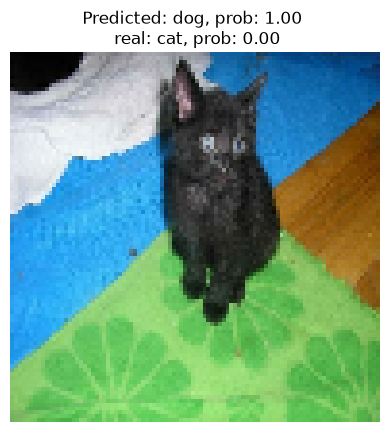

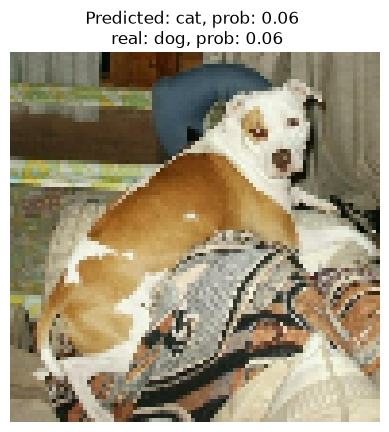


--- Extreme errors (lowest probability for the real class) ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━

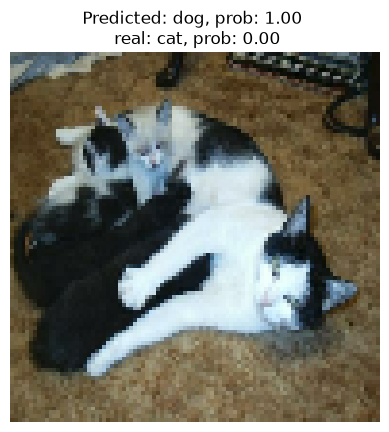

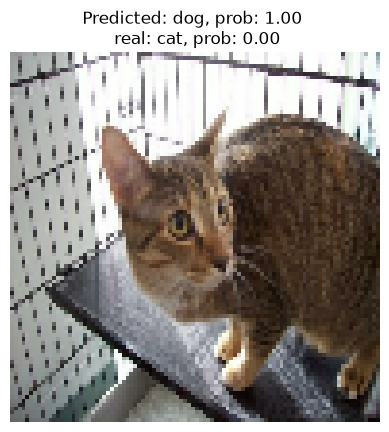

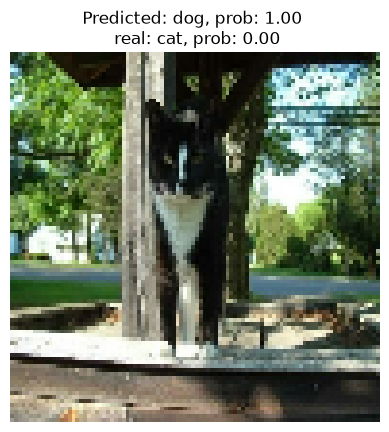

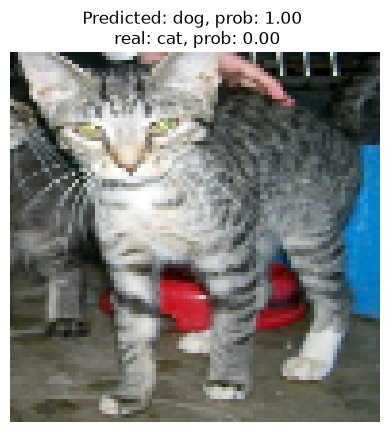

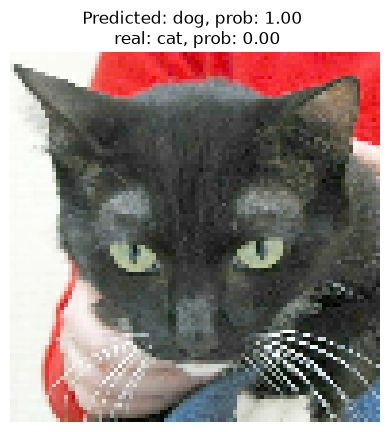

In [17]:
import pandas as pd

def show_loss_accuracy_evolution(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Binary Crossentropy')
    ax1.plot(hist['epoch'], hist['loss'], label='Train Error')
    ax1.plot(hist['epoch'], hist['val_loss'], label='Val Error')
    ax1.grid()
    ax1.legend()

    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.plot(hist['epoch'], hist['accuracy'], label='Train Accuracy')
    ax2.plot(hist['epoch'], hist['val_accuracy'], label='Val Accuracy')
    ax2.grid()
    ax2.legend()

    plt.show()


def show_errors(val_ds, model, class_names, n_images=10):
    """Display the first n_images misclassified samples."""
    n_plots = 0
    for images, labels in val_ds:
        pred_prob = model.predict(images)
        preds = (1.0 * (pred_prob >= 0.5)).astype(np.int32).flatten()
        bad_pred_inds = np.where(preds != labels)[0]
        for ind in list(bad_pred_inds):
            n_plots += 1
            real_class = class_names[labels[ind].numpy()]
            pred_class = class_names[preds[ind]]
            prob = pred_prob[ind][0]
            prob_real = prob if labels[ind].numpy() == 1 else 1 - prob
            plt.imshow(images[ind].numpy().astype("uint8"))
            plt.title('Predicted: {0}, prob: {1:.2f} \n real: {2}, prob: {3:.2f}'.format(
                pred_class, prob, real_class, prob_real))
            plt.axis('off')
            plt.show()

            if n_plots == n_images:
                return


def show_extreme_errors(val_ds, model, class_names, n_images=10):
    """Display the n_images misclassified samples with lowest probability for the real class."""
    errors = []
    for images, labels in val_ds:
        pred_prob = model.predict(images)
        preds = (1.0 * (pred_prob >= 0.5)).astype(np.int32).flatten()
        bad_pred_inds = np.where(preds != labels)[0]
        for ind in bad_pred_inds:
            label = labels[ind].numpy()
            prob = pred_prob[ind][0]
            prob_real = prob if label == 1 else 1 - prob
            errors.append({
                'image': images[ind].numpy(),
                'real_label': label,
                'pred_label': preds[ind],
                'prob': prob,
                'prob_real': prob_real,
            })

    errors.sort(key=lambda x: x['prob_real'])

    for err in errors[:n_images]:
        real_class = class_names[err['real_label']]
        pred_class = class_names[err['pred_label']]
        plt.imshow(err['image'].astype("uint8"))
        plt.title('Predicted: {0}, prob: {1:.2f} \n real: {2}, prob: {3:.2f}'.format(
            pred_class, err['prob'], real_class, err['prob_real']))
        plt.axis('off')
        plt.show()


show_loss_accuracy_evolution(history)
show_errors(test_ds, model_1, class_names, n_images=5)
print('\n--- Extreme errors (lowest probability for the real class) ---')
show_extreme_errors(test_ds, model_1, class_names, n_images=5)